<a href="https://colab.research.google.com/github/linatris18-hub/TP-Classification-Crop-Recommendation/blob/main/TP_Classification_Crop_Recommendation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import pandas as pd
import zipfile

# Décompresser le fichier archive.zip
with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

# Charger le jeu de données
df = pd.read_csv('Crop_recommendation.csv')

# Afficher les premières lignes
print(df.head())

    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


In [ ]:
# Dimensions du dataset
print("Dimensions :", df.shape)

# Informations générales
df.info()

Dimensions : (2200, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [ ]:
# Vérifier les valeurs manquantes
print(df.isnull().sum())

# Nombre de classes
print("Nombre de classes :", df['label'].nunique())

# Distribution des classes
print(df['label'].value_counts())

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Nombre de classes : 22
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


In [ ]:
# Séparation des variables indépendantes et dépendante

X = df.drop('label', axis=1)
y = df['label']
print("Dimensions de X :", X.shape)
print("Dimensions de Y :", y.shape)


Dimensions de X : (2200, 7)
Dimensions de Y : (2200,)


In [ ]:
print("Variables X :")
print(X.head())

print("\nVariable Y :")
print(y.head())

Variables X :
    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340

Variable Y :
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: object


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Classes :", le.classes_)
print("Nombre de classes :", len(le.classes_))

Classes : ['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']
Nombre de classes : 22


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Création du modèle
model_100 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Entraînement sur 100% des données
model_100.fit(X, y_encoded)

print("Entraînement terminé avec succès !")

Entraînement terminé avec succès !


In [ ]:
# Prédictions
y_pred_100 = model_100.predict(X)

print("Les prédictions sont terminées.")

Les prédictions sont terminées.


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

accuracy_100 = accuracy_score(y_encoded, y_pred_100)

precision_100 = precision_score(
    y_encoded, y_pred_100, average='weighted'
)

recall_100 = recall_score(
    y_encoded, y_pred_100, average='weighted'
)

f1_100 = f1_score(
    y_encoded, y_pred_100, average='weighted'
)

print("Accuracy :", accuracy_100)
print("Precision :", precision_100)
print("Recall :", recall_100)
print("F1-score :", f1_100)

Accuracy : 1.0
Precision : 1.0
Recall : 1.0
F1-score : 1.0


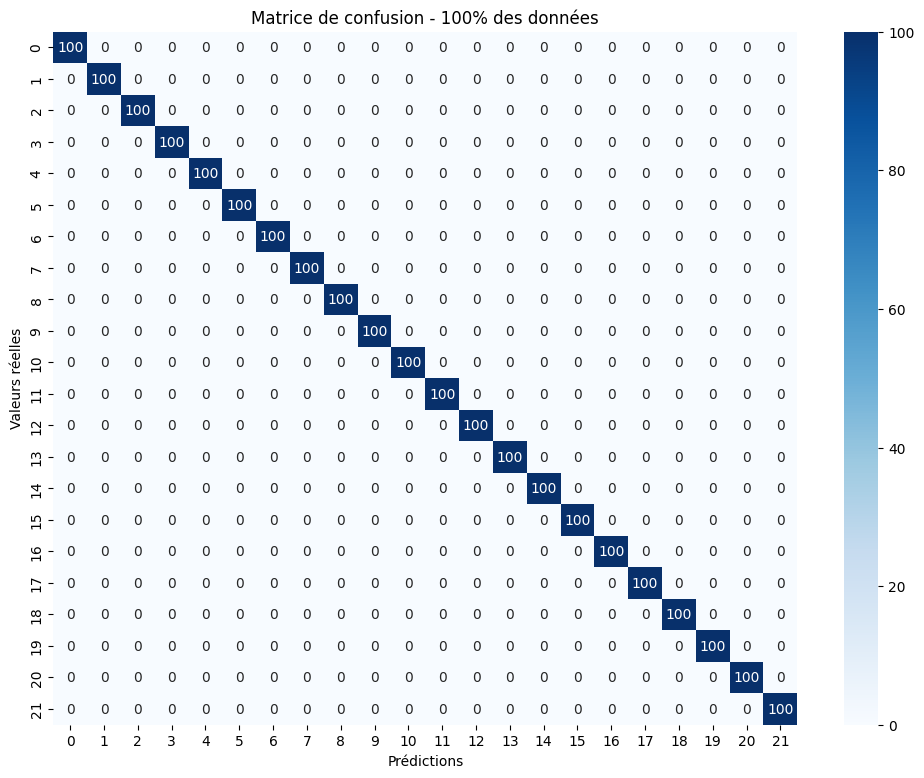

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_encoded, y_pred_100)

plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Matrice de confusion - 100% des données")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

In [ ]:
print("Accuracy :", accuracy_100 * 100, "%")
print("Precision :", precision_100 * 100, "%")
print("Recall :", recall_100 * 100, "%")
print("F1-score :", f1_100 * 100, "%")

Accuracy : 100.0 %
Precision : 100.0 %
Recall : 100.0 %
F1-score : 100.0 %


In [ ]:
from sklearn.model_selection import train_test_split

X_train_50, X_test_50, y_train_50, y_test_50 = train_test_split(
    X, y_encoded,
    train_size=0.5,
    random_state=42,
    stratify=y_encoded
)

print("Données d'entraînement :", X_train_50.shape)
print("Données de test :", X_test_50.shape)

Données d'entraînement : (1100, 7)
Données de test : (1100, 7)


In [ ]:
model_50 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_50.fit(X_train_50, y_train_50)

print("Entraînement avec 50% terminé !")

Entraînement avec 50% terminé !


In [ ]:
y_pred_50 = model_50.predict(X_test_50)

In [ ]:
accuracy_50 = accuracy_score(y_test_50, y_pred_50)

precision_50 = precision_score(
    y_test_50, y_pred_50, average='weighted'
)

recall_50 = recall_score(
    y_test_50, y_pred_50, average='weighted'
)

f1_50 = f1_score(
    y_test_50, y_pred_50, average='weighted'
)

print("Accuracy :", accuracy_50 * 100, "%")
print("Precision :", precision_50 * 100, "%")
print("Recall :", recall_50 * 100, "%")
print("F1-score :", f1_50 * 100, "%")

Accuracy : 99.27272727272727 %
Precision : 99.30315560567661 %
Recall : 99.27272727272727 %
F1-score : 99.27210815487145 %


In [ ]:
print("Différence entre les deux expériences :")

print("Accuracy :", accuracy_100 - accuracy_50)
print("Precision :", precision_100 - precision_50)
print("Recall :", recall_100 - recall_50)
print("F1-score :", f1_100 - f1_50)

Différence entre les deux expériences :
Accuracy : 0.0072727272727273196
Precision : 0.006968443943233926
Recall : 0.0072727272727273196
F1-score : 0.0072789184512855876


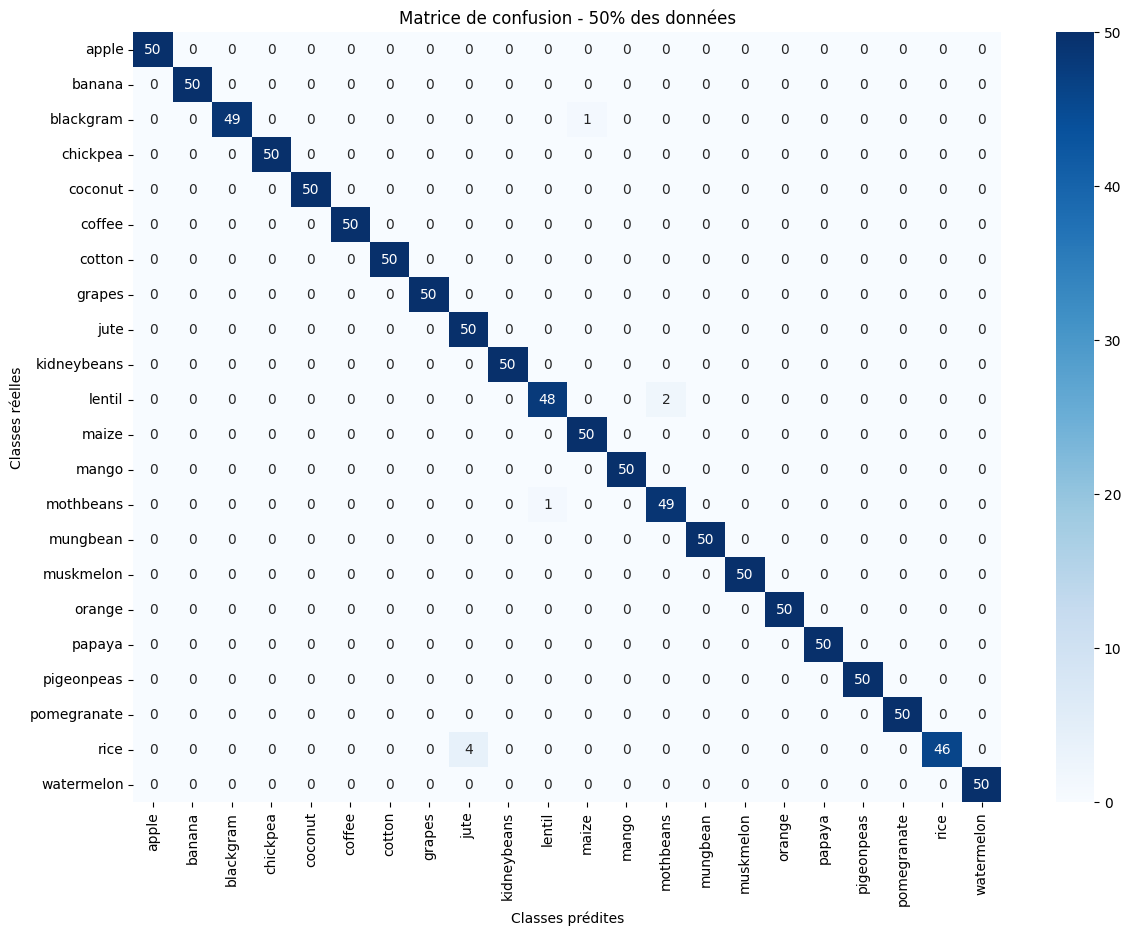

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_50 = confusion_matrix(y_test_50, y_pred_50)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm_50,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Matrice de confusion - 50% des données")
plt.xlabel("Classes prédites")
plt.ylabel("Classes réelles")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

In [ ]:
print(classification_report(
    y_test_50,
    y_pred_50,
    target_names=le.classes_
))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        50
      banana       1.00      1.00      1.00        50
   blackgram       1.00      0.98      0.99        50
    chickpea       1.00      1.00      1.00        50
     coconut       1.00      1.00      1.00        50
      coffee       1.00      1.00      1.00        50
      cotton       1.00      1.00      1.00        50
      grapes       1.00      1.00      1.00        50
        jute       0.93      1.00      0.96        50
 kidneybeans       1.00      1.00      1.00        50
      lentil       0.98      0.96      0.97        50
       maize       0.98      1.00      0.99        50
       mango       1.00      1.00      1.00        50
   mothbeans       0.96      0.98      0.97        50
    mungbean       1.00      1.00      1.00        50
   muskmelon       1.00      1.00      1.00        50
      orange       1.00      1.00      1.00        50
      papaya       1.00    

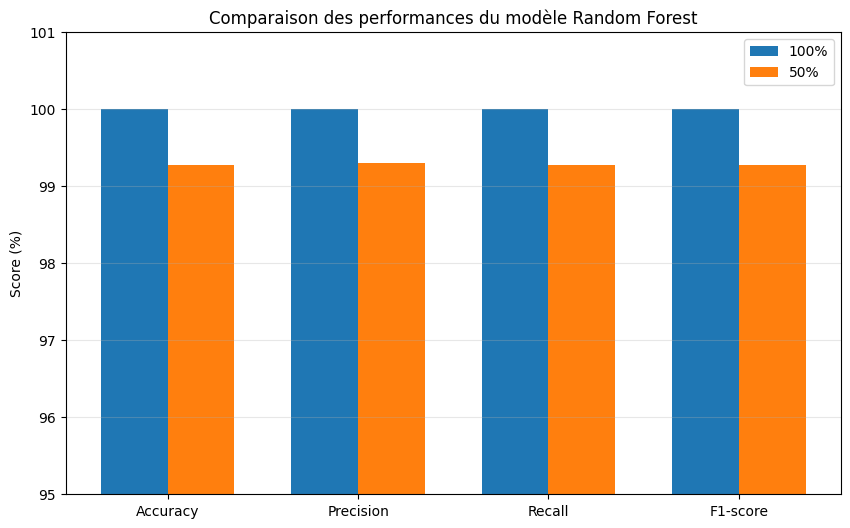

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']

results_100 = [
    accuracy_100 * 100,
    precision_100 * 100,
    recall_100 * 100,
    f1_100 * 100
]

results_50 = [
    accuracy_50 * 100,
    precision_50 * 100,
    recall_50 * 100,
    f1_50 * 100
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, results_100, width, label='100%')
plt.bar(x + width/2, results_50, width, label='50%')

plt.ylabel('Score (%)')
plt.title('Comparaison des performances du modèle Random Forest')
plt.xticks(x, metrics)
plt.ylim(95, 101)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Séparation des données : 80% entraînement et 20% test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Données d'entraînement :", X_train.shape)
print("Données de test :", X_test.shape)

Données d'entraînement : (1760, 7)
Données de test : (440, 7)


In [ ]:
model_full = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_full.fit(X_train, y_train)

y_pred_full = model_full.predict(X_test)

print("Entraînement avec 100% terminé")

Entraînement avec 100% terminé


In [ ]:
X_train_half, _, y_train_half, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.5,
    random_state=42,
    stratify=y_train
)

model_half = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_half.fit(X_train_half, y_train_half)

y_pred_half = model_half.predict(X_test)

print("Entraînement avec 50% terminé")

Entraînement avec 50% terminé


In [ ]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

results = {
    "100% des données": [
        accuracy_score(y_test, y_pred_full),
        precision_score(y_test, y_pred_full, average='weighted'),
        recall_score(y_test, y_pred_full, average='weighted'),
        f1_score(y_test, y_pred_full, average='weighted')
    ],

    "50% des données": [
        accuracy_score(y_test, y_pred_half),
        precision_score(y_test, y_pred_half, average='weighted'),
        recall_score(y_test, y_pred_half, average='weighted'),
        f1_score(y_test, y_pred_half, average='weighted')
    ]
}

comparison = pd.DataFrame(
    results,
    index=['Accuracy', 'Precision', 'Recall', 'F1-score']
)

print(comparison * 100)

           100% des données  50% des données
Accuracy          99.545455        99.772727
Precision         99.567100        99.783550
Recall            99.545455        99.772727
F1-score          99.545170        99.772585


In [ ]:
import joblib

joblib.dump(model_full, 'random_forest_100_percent.pkl')
joblib.dump(model_half, 'random_forest_50_percent.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("Les modèles ont été sauvegardés avec succès.")

Les modèles ont été sauvegardés avec succès.


In [ ]:
comparison_percent = comparison * 100

comparison_percent.to_csv('comparaison_resultats.csv')

print("Le tableau des résultats a été sauvegardé.")

Le tableau des résultats a été sauvegardé.


In [ ]:
import os

print(os.listdir())

['.config', 'random_forest_100_percent.pkl', 'Crop_recommendation.csv', 'random_forest_50_percent.pkl', 'comparaison_resultats.csv', 'archive.zip', 'label_encoder.pkl', 'sample_data']
